In [8]:
%pip install -q -U ultralytics roboflow python-dotenv


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
from roboflow import Roboflow
from pathlib import Path
from dotenv import load_dotenv
import os
from ultralytics import YOLO
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# La clave se carga desde el archivo local apikeys.env; no la escribas en el notebook.
# El archivo esperado es notebooks/lecture8/yolo/apikeys.env y debe contener:
#   ROBOFLOW_API_KEY=tu_clave_privada_de_roboflow
ENV_PATH = next(
    (
        candidate
        for base_dir in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            base_dir / "apikeys.env",
            base_dir / "notebooks" / "lecture8" / "yolo" / "apikeys.env",
        )
        if candidate.is_file()
    ),
    None,
)
if ENV_PATH is None or not load_dotenv(dotenv_path=ENV_PATH):
    raise RuntimeError(
        "No se encontro apikeys.env. Colocalo junto al notebook en "
        "notebooks/lecture8/yolo/apikeys.env"
    )

api_key = os.getenv("ROBOFLOW_API_KEY")
if not api_key:
    raise RuntimeError(
        f"No se encontro ROBOFLOW_API_KEY en {ENV_PATH}. "
        "Verifica que el archivo contenga ROBOFLOW_API_KEY=tu_clave_privada_de_roboflow"
    )

In [10]:
rf = Roboflow(api_key=api_key)
project = rf.workspace("semilleroml").project("sitesafety-pbakq")
dataset = project.version(1).download("yolo26")

print(f"Dataset descargado en: {dataset.location}")

loading Roboflow workspace...
loading Roboflow project...
Dataset descargado en: c:\General\Eafit\Semestre8\IA\si3003-artificial-intelligence\notebooks\lecture8\yolo\SiteSafety-1


In [11]:
# Load a model
model = YOLO("yolo26n.pt")  # load a pretrained model (recommended for training)

# Train the model
# Ruta portable: usamos dataset.location (definido en la celda anterior) en vez de
# una ruta absoluta especifica de una maquina/Studio, para que el notebook funcione
# en cualquier entorno donde se haya corrido la celda de descarga.
results = model.train(data=f"{dataset.location}/data.yaml", epochs=20)

Ultralytics 8.4.177  Python-3.13.2 torch-2.14.1+cpu CPU (AMD Ryzen 5 4600H with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\General\Eafit\Semestre8\IA\si3003-artificial-intelligence\notebooks\lecture8\yolo\SiteSafety-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mos

In [12]:
import glob

# Ruta portable: tomamos la primera imagen del set de test que se descargo con Roboflow,
# en vez de una ruta absoluta especifica de una maquina/Studio.
test_images = sorted(glob.glob(f"{dataset.location}/test/images/*.jpg"))
assert test_images, f"No se encontraron imagenes de test en {dataset.location}/test/images"
image_path = test_images[0]
print(f"Usando imagen de prueba: {image_path}")

resultados = model(image_path, conf=0.001, iou=0.7)

Usando imagen de prueba: c:\General\Eafit\Semestre8\IA\si3003-artificial-intelligence\notebooks\lecture8\yolo\SiteSafety-1/test/images\00596_jpg.rf.069990c2f14e9a321e05f3d069869555.jpg

image 1/1 c:\General\Eafit\Semestre8\IA\si3003-artificial-intelligence\notebooks\lecture8\yolo\SiteSafety-1\test\images\00596_jpg.rf.069990c2f14e9a321e05f3d069869555.jpg: 640x640 53 helmets, 247 vests, 74.0ms
Speed: 5.0ms preprocess, 74.0ms inference, 7.3ms postprocess per image at shape (1, 3, 640, 640)


In [13]:
r = resultados[0] # r es un objeto de tipo 'ultralytics.yolo.engine.results.Results' que contiene toda la informacion de la inferencia

print("=== Informacion general ===")
print(f"Imagen original: {r.path}")
print(f"Tamano procesado: {r.orig_shape}")
print(f"Objetos detectados: {len(r.boxes)}")


print("\n=== Detecciones ===")
for i, box in enumerate(r.boxes):
    clase_id  = int(box.cls[0])
    clase_nom = model.names[clase_id]
    confianza = float(box.conf[0])
    x1, y1, x2, y2 = box.xyxy[0].tolist()
    
    print(f"  [{i+1}] {clase_nom:15s} | confianza: {confianza:.2f} | bbox: ({x1:.0f},{y1:.0f}) → ({x2:.0f},{y2:.0f})")

=== Informacion general ===
Imagen original: c:\General\Eafit\Semestre8\IA\si3003-artificial-intelligence\notebooks\lecture8\yolo\SiteSafety-1\test\images\00596_jpg.rf.069990c2f14e9a321e05f3d069869555.jpg
Tamano procesado: (640, 640)
Objetos detectados: 300

=== Detecciones ===
  [1] helmet          | confianza: 0.48 | bbox: (214,95) → (314,277)
  [2] vest            | confianza: 0.44 | bbox: (42,318) → (237,640)
  [3] helmet          | confianza: 0.41 | bbox: (229,104) → (302,283)
  [4] helmet          | confianza: 0.38 | bbox: (180,102) → (316,282)
  [5] vest            | confianza: 0.34 | bbox: (230,107) → (300,281)
  [6] vest            | confianza: 0.29 | bbox: (339,222) → (493,411)
  [7] helmet          | confianza: 0.29 | bbox: (231,106) → (303,215)
  [8] helmet          | confianza: 0.28 | bbox: (490,83) → (640,350)
  [9] helmet          | confianza: 0.27 | bbox: (0,0) → (112,143)
  [10] vest            | confianza: 0.27 | bbox: (530,74) → (595,212)
  [11] helmet          | con

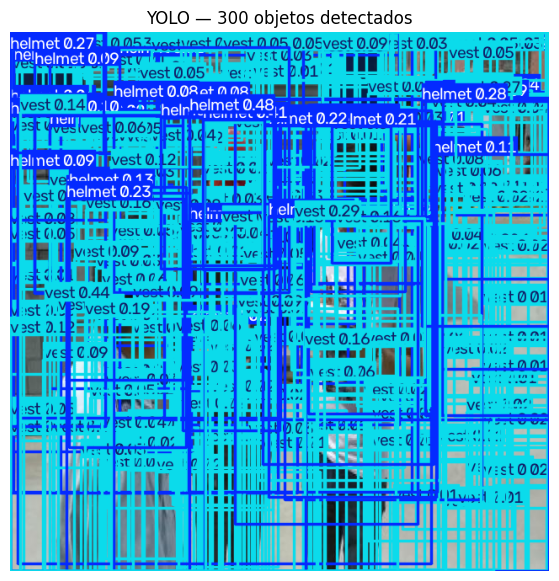

In [14]:
# r.plot() retorna la imagen anotada como array NumPy (BGR → convertir a RGB para matplotlib)
imagen_anotada = r.plot()
imagen_anotada_rgb = imagen_anotada[:, :, ::-1]  # BGR a RGB

plt.figure(figsize=(12, 7))
plt.imshow(imagen_anotada_rgb)
plt.title(f"YOLO — {len(r.boxes)} objetos detectados")
plt.axis("off")
plt.show()